# Bloc 2 — Simulation d'un problème de régression

**Problème simulé :** prédire le **prix de vente d'un logement** (en €) à partir de ses
caractéristiques (surface, quartier, âge, DPE...). Les données sont **générées** : on connaît
donc la « vraie » formule, ce qui permet de vérifier ce que les modèles apprennent.

Démarche complète :
1. Simulation des données
2. Exploration rapide
3. Découpage train / test (avant tout traitement → pas de fuite)
4. Préparation des données dans un `Pipeline` (imputation, mise à l'échelle, encodage)
5. Comparaison de modèles en validation croisée
6. Optimisation des hyperparamètres avec `GridSearchCV`
7. Évaluation finale sur le jeu de test et analyse des erreurs
8. Interprétation (importance des variables) et courbe d'apprentissage
9. Sauvegarde et prédiction sur de nouveaux biens

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV, KFold, cross_validate, learning_curve, train_test_split,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
SEED = 42

## 1. Simulation des données

Règles utilisées pour fabriquer le prix (le modèle ne les connaît pas) :
- un **prix au m²** qui dépend du quartier (Centre > Péricentre > Banlieue > Campagne) ;
- un effet **non linéaire** de l'âge : décote jusqu'à ~60 ans, puis légère prime pour l'ancien « de caractère » ;
- une décote avec la **distance** au centre et avec un **mauvais DPE** (E, F, G) ;
- un bonus **parking** et **maison** ;
- un **bruit multiplicatif** (~12 %) : deux biens identiques ne se vendent pas au même prix.

On ajoute aussi des **valeurs manquantes** (âge inconnu, DPE non renseigné) pour avoir un cas réaliste.

In [2]:
def simulate_housing(n: int = 3000, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    quartier = rng.choice(["Centre", "Péricentre", "Banlieue", "Campagne"], size=n, p=[0.2, 0.35, 0.3, 0.15])
    p_maison = pd.Series(quartier).map({"Centre": 0.1, "Péricentre": 0.3, "Banlieue": 0.6, "Campagne": 0.85})
    maison = rng.random(n) < p_maison.to_numpy()

    surface = np.where(maison, rng.normal(110, 30, n), rng.normal(60, 20, n)).clip(15, 300).round()
    nb_pieces = (surface / 22 + rng.normal(0, 0.7, n)).round().clip(1, 10).astype(int)
    age = rng.integers(0, 120, n)
    distance_bornes = {"Centre": (0, 2), "Péricentre": (2, 6), "Banlieue": (6, 15), "Campagne": (15, 40)}
    distance = np.array([rng.uniform(*distance_bornes[q]) for q in quartier]).round(1)
    # Les vieux logements ont plus souvent un mauvais DPE
    dpe_score = (age / 120 * 4 + rng.normal(0, 1.2, n)).clip(0, 6).round().astype(int)
    dpe = np.array(list("ABCDEFG"))[dpe_score]
    parking = rng.random(n) < np.where(maison, 0.8, 0.35)

    # --- Formule « cachée » du prix ---
    prix_m2 = pd.Series(quartier).map({"Centre": 5500, "Péricentre": 4200, "Banlieue": 3000, "Campagne": 2000}).to_numpy()
    effet_age = np.where(age <= 60, 1 - 0.004 * age, 0.76 + 0.003 * (age - 60))
    effet_distance = np.exp(-0.01 * distance)
    effet_dpe = pd.Series(dpe).map({"A": 1.05, "B": 1.03, "C": 1.0, "D": 0.98, "E": 0.94, "F": 0.88, "G": 0.82}).to_numpy()
    bruit = rng.lognormal(mean=0, sigma=0.12, size=n)
    prix = (surface * prix_m2 * effet_age * effet_distance * effet_dpe * np.where(maison, 1.05, 1.0)
            + parking * 15_000) * bruit

    df = pd.DataFrame(data={
        "surface": surface,
        "nb_pieces": nb_pieces,
        "age": age.astype(float),
        "distance_centre_km": distance,
        "quartier": quartier,
        "type_bien": np.where(maison, "Maison", "Appartement"),
        "dpe": dpe,
        "parking": parking.astype(int),
        "prix": prix.round(-2),
    })
    # Valeurs manquantes aléatoires (MCAR)
    df.loc[rng.random(n) < 0.08, "age"] = np.nan
    df.loc[rng.random(n) < 0.05, "dpe"] = np.nan
    return df


df = simulate_housing()
print(df.shape)
df.head()

(3000, 9)


,surface,nb_pieces,age,distance_centre_km,quartier,type_bien,dpe,parking,prix
0,52.000,2,27.000,11.900,Banlieue,Appartement,B,0,"147,000.000"
1,37.000,2,31.000,4.000,Péricentre,Appartement,C,0,"192,100.000"
2,92.000,5,NaN,24.800,Campagne,Maison,C,1,"98,300.000"
3,60.000,3,60.000,14.500,Banlieue,Appartement,B,0,"126,400.000"
4,101.000,5,NaN,1.400,Centre,Maison,D,1,"528,900.000"


## 2. Exploration rapide

In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   surface             3000 non-null   float64
 1   nb_pieces           3000 non-null   int64  
 2   age                 2759 non-null   float64
 3   distance_centre_km  3000 non-null   float64
 4   quartier            3000 non-null   object 
 5   type_bien           3000 non-null   object 
 6   dpe                 2835 non-null   object 
 7   parking             3000 non-null   int64  
 8   prix                3000 non-null   float64
dtypes: float64(4), int64(2), object(3)
memory usage: 211.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
surface,"3,000.000",NaN,NaN,NaN,81.448,35.453,15.000,55.000,76.000,104.000,231.000
nb_pieces,"3,000.000",NaN,NaN,NaN,3.727,1.732,1.000,2.000,4.000,5.000,10.000
age,"2,759.000",NaN,NaN,NaN,59.983,35.025,0.000,29.000,60.000,90.000,119.000
distance_centre_km,"3,000.000",NaN,NaN,NaN,8.885,9.205,0.000,2.500,5.400,12.100,40.000
quartier,3000,4,Péricentre,1044,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_bien,3000,2,Appartement,1708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dpe,2835,7,C,630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parking,"3,000.000",NaN,NaN,NaN,0.555,0.497,0.000,0.000,1.000,1.000,1.000
prix,"3,000.000",NaN,NaN,NaN,"252,961.467","132,361.308","17,500.000","156,700.000","227,300.000","323,125.000","999,000.000"


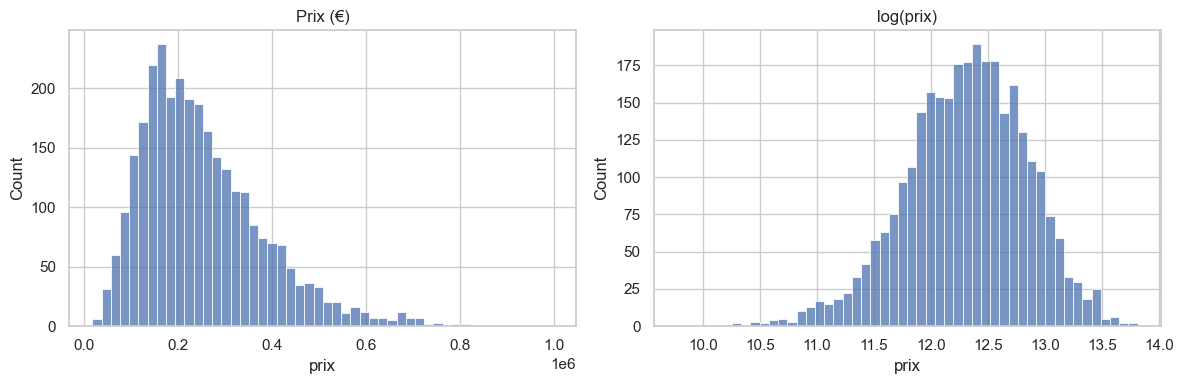

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.histplot(data=df, x="prix", bins=50, ax=axes[0]).set_title("Prix (€)")
sns.histplot(x=np.log(df["prix"]), bins=50, ax=axes[1]).set_title("log(prix)")
plt.tight_layout()

**Constat :** le prix est **asymétrique à droite** (quelques biens très chers), son logarithme
est presque symétrique. Comme le prix est construit par **multiplication** d'effets,
modéliser `log(prix)` rend la relation plus **linéaire** → piste à tester (§5).

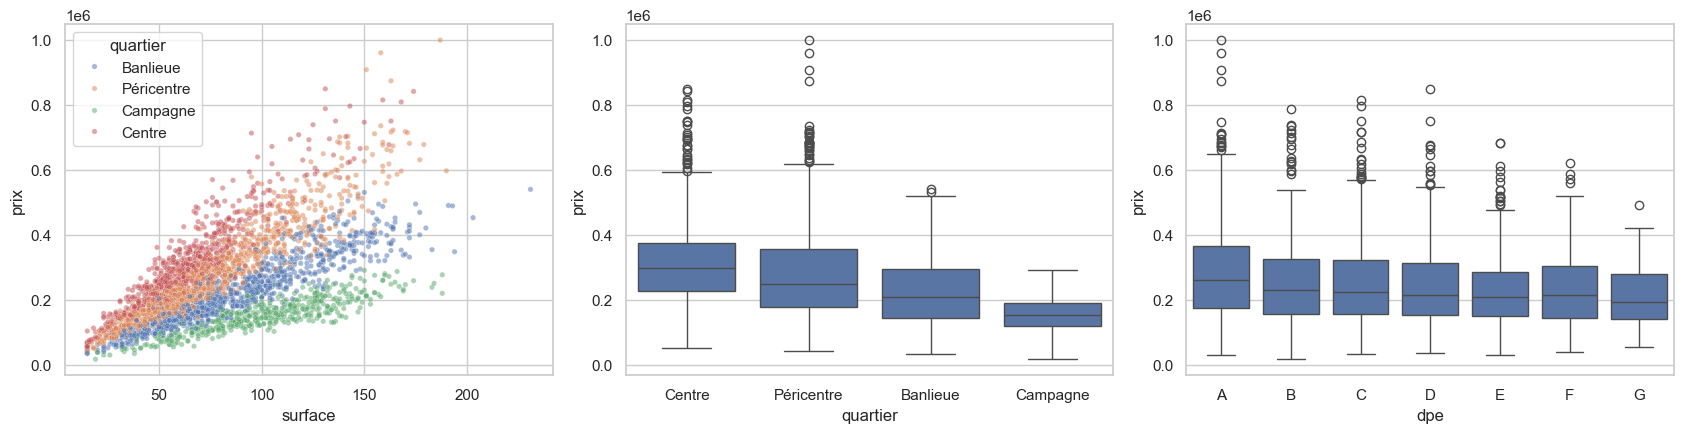

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="surface", y="prix", hue="quartier", alpha=0.5, s=15, ax=axes[0])
sns.boxplot(data=df, x="quartier", y="prix", order=["Centre", "Péricentre", "Banlieue", "Campagne"], ax=axes[1])
sns.boxplot(data=df, x="dpe", y="prix", order=list("ABCDEFG"), ax=axes[2])
plt.tight_layout()

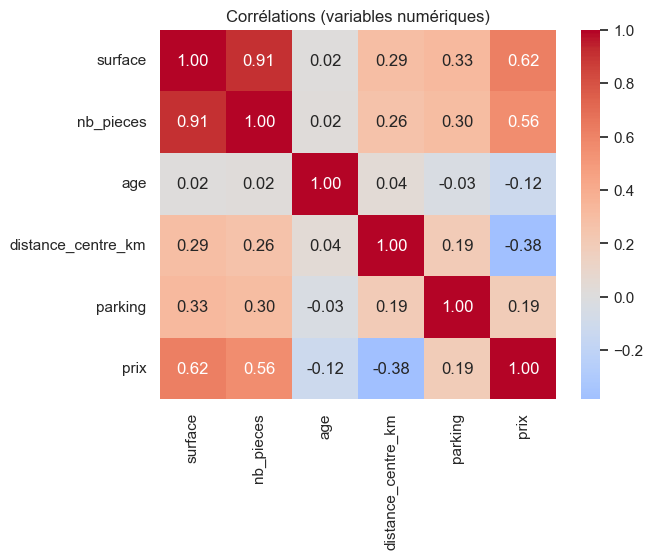

In [6]:
num_df = df.select_dtypes(include="number")
sns.heatmap(data=num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations (variables numériques)");

**Constats :**
- la **surface** est la variable la plus liée au prix, mais la pente dépend du **quartier**
  (interaction) → un modèle linéaire simple aura du mal ;
- `surface` et `nb_pieces` sont très corrélées (**colinéarité**) → intérêt de la régularisation (Ridge/Lasso) ;
- les variables catégorielles (`quartier`, `type_bien`, `dpe`) devront être **encodées**.

## 3. Découpage train / test

On isole le jeu de test **tout de suite** : toutes les étapes d'apprentissage (imputation,
mise à l'échelle, choix du modèle, hyperparamètres) se font uniquement sur le train.
Le test sert **une seule fois**, à la fin, pour estimer la performance réelle.

In [7]:
TARGET = "prix"
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"train : {X_train.shape}   test : {X_test.shape}")

train : (2400, 8)   test : (600, 8)


## 4. Préparation des données dans un pipeline

`ColumnTransformer` applique un traitement différent selon le type de colonne :

| Colonnes | Étapes |
|---|---|
| numériques | `SimpleImputer(median)` → `StandardScaler` |
| catégorielles | `SimpleImputer(most_frequent)` → `OneHotEncoder` |

Intérêt du `Pipeline` : les statistiques (médiane, moyenne, écart-type, modalités) sont
**apprises sur le pli d'entraînement uniquement** à chaque validation croisée → **pas de fuite
de données**, et un seul objet à sauvegarder et déployer.

In [8]:
NUM_COLS = ["surface", "nb_pieces", "age", "distance_centre_km", "parking"]
CAT_COLS = ["quartier", "type_bien", "dpe"]

preprocess = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUM_COLS),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CAT_COLS),
])


def make_pipeline(model) -> Pipeline:
    return Pipeline(steps=[("preprocess", preprocess), ("model", model)])


make_pipeline(LinearRegression())  # affichage interactif du pipeline

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [9]:
# Ce que voit le modèle après transformation
fitted_preprocess = preprocess.fit(X_train)
print(fitted_preprocess.transform(X_train).shape)
fitted_preprocess.get_feature_names_out()

(2400, 18)


array(['num__surface', 'num__nb_pieces', 'num__age',
       'num__distance_centre_km', 'num__parking',
       'cat__quartier_Banlieue', 'cat__quartier_Campagne',
       'cat__quartier_Centre', 'cat__quartier_Péricentre',
       'cat__type_bien_Appartement', 'cat__type_bien_Maison',
       'cat__dpe_A', 'cat__dpe_B', 'cat__dpe_C', 'cat__dpe_D',
       'cat__dpe_E', 'cat__dpe_F', 'cat__dpe_G'], dtype=object)

## 5. Comparaison de modèles en validation croisée

**Métriques de régression :**

| Métrique | Lecture | Remarque |
|---|---|---|
| **MAE** | erreur absolue moyenne, en € | robuste, facile à expliquer |
| **RMSE** | racine de l'erreur quadratique moyenne, en € | pénalise davantage les grosses erreurs (RMSE ≥ MAE) |
| **R²** | part de la variance expliquée (1 = parfait, 0 = prédire la moyenne) | sans unité, comparable entre problèmes |
| **MAPE** | erreur relative moyenne, en % | parlant pour le métier, instable si y proche de 0 |

`scikit-learn` **maximise** toujours un score → les erreurs sont renvoyées en négatif
(`neg_root_mean_squared_error`), on les repasse en positif.

**Modèles comparés :** une **baseline** (prédire la moyenne), des modèles **linéaires**
(dont un sur `log(prix)` via `TransformedTargetRegressor`), un modèle à **distance** (KNN),
un **arbre** et deux **ensembles** d'arbres.

In [10]:
models = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "Linéaire sur log(prix)": TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Lasso (alpha=100)": Lasso(alpha=100, max_iter=10_000),
    "KNN (k=10)": KNeighborsRegressor(n_neighbors=10),
    "Arbre (profondeur 8)": DecisionTreeRegressor(max_depth=8, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "MAPE": "neg_mean_absolute_percentage_error",
    "R2": "r2",
}

rows, fold_scores = [], []
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    rows.append({
        "modèle": name,
        "RMSE": -res["test_RMSE"].mean(),
        "RMSE (écart-type)": res["test_RMSE"].std(),
        "MAE": -res["test_MAE"].mean(),
        "MAPE (%)": -res["test_MAPE"].mean() * 100,
        "R2": res["test_R2"].mean(),
        "R2 train": res["train_R2"].mean(),
        "temps fit (s)": res["fit_time"].mean(),
    })
    fold_scores += [{"modèle": name, "RMSE": -s} for s in res["test_RMSE"]]

cv_results = pd.DataFrame(data=rows).set_index("modèle").sort_values(by="RMSE")
cv_results

,RMSE,RMSE (écart-type),MAE,MAPE (%),R2,R2 train,temps fit (s)
modèle,,,,,,,
Gradient Boosting,"39,148.449","2,904.652","27,788.173",11.593,0.911,0.942,0.200
Random Forest,"41,737.322","3,257.374","29,333.562",12.156,0.899,0.987,0.238
Arbre (profondeur 8),"50,010.344","3,037.550","34,879.028",14.489,0.855,0.951,0.014
KNN (k=10),"53,120.323","3,996.325","38,478.567",18.305,0.837,0.871,0.006
Régression linéaire,"54,317.903","2,335.339","40,853.710",21.745,0.830,0.834,0.006
Lasso (alpha=100),"54,324.568","2,381.506","40,779.336",21.621,0.830,0.834,0.006
Ridge (alpha=10),"54,546.213","2,473.747","40,686.634",21.381,0.829,0.832,0.006
Linéaire sur log(prix),"56,146.035","5,780.042","36,900.046",15.529,0.818,0.821,0.008
Baseline (moyenne),"132,087.623","6,341.051","101,819.146",56.746,-0.003,0.000,0.006


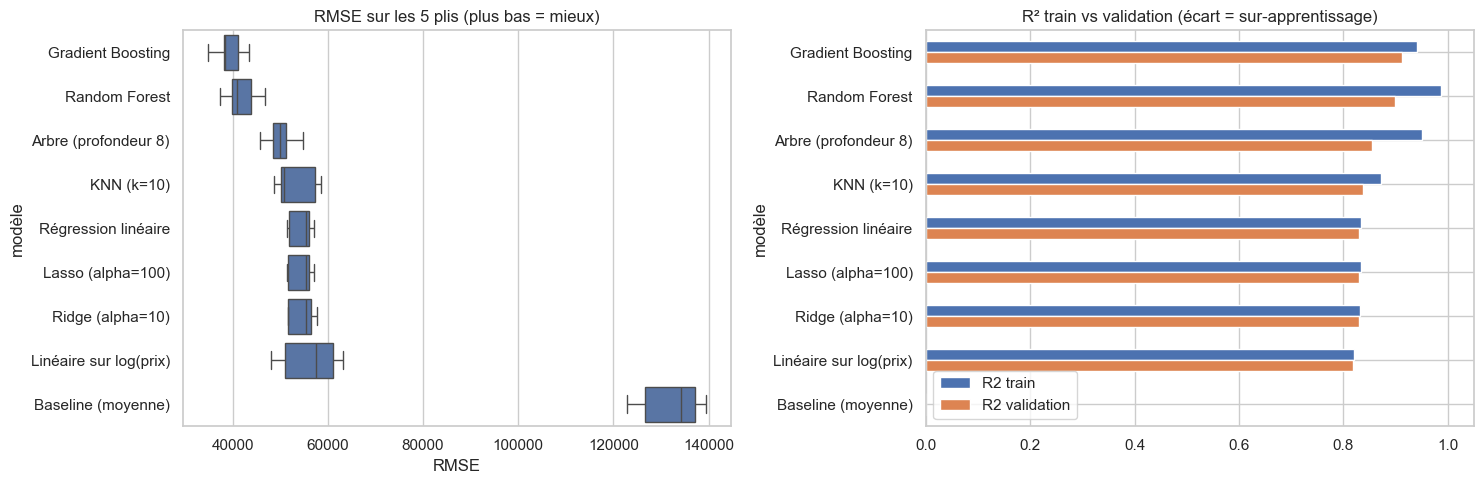

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
order = cv_results.index

sns.boxplot(data=pd.DataFrame(data=fold_scores), y="modèle", x="RMSE", order=order, ax=axes[0])
axes[0].set_title("RMSE sur les 5 plis (plus bas = mieux)")

cv_results.loc[order, ["R2 train", "R2"]].rename(columns={"R2": "R2 validation"}).plot.barh(ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1.05)
axes[1].set_title("R² train vs validation (écart = sur-apprentissage)")
plt.tight_layout()

**Lecture :**
- la **baseline** donne le niveau à battre : un modèle utile doit faire nettement mieux ;
- passer en **`log(prix)`** améliore nettement les erreurs **relatives** du modèle linéaire
  (MAPE et MAE en baisse) mais **dégrade la RMSE** : en optimisant le log, le modèle soigne
  les petits biens et commet de plus grosses erreurs en € sur les biens chers, que la RMSE
  pénalise fortement → **le « meilleur » modèle dépend de la métrique choisie** (à décider avec le métier) ;
- Ridge / Lasso changent peu ici (beaucoup de données, peu de variables) : la régularisation
  sert surtout quand il y a beaucoup de variables ou de la colinéarité forte ;
- l'**arbre seul** sur-apprend (R² train ≫ R² validation), les **ensembles** (Random Forest,
  Gradient Boosting) captent les non-linéarités et interactions sans réglage particulier ;
- l'écart-type entre plis indique si la différence entre deux modèles est **significative**.

## 6. Optimisation des hyperparamètres avec `GridSearchCV`

On optimise le **Gradient Boosting** (meilleur candidat ou proche du meilleur).

- Les paramètres se nomment `<étape>__<sous-étape>__<paramètre>` : on peut régler le
  **modèle** (`model__...`) **et le prétraitement** (`preprocess__num__imputer__strategy`) en même temps.
- Chaque combinaison est évaluée en validation croisée (5 plis) sur le **train** uniquement.
- `refit="RMSE"` : le meilleur modèle est réentraîné sur tout le train avec les meilleurs paramètres.

In [12]:
param_grid = {
    "preprocess__num__imputer__strategy": ["median", "mean"],
    "model__n_estimators": [200, 400],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3, 4],
}
n_combi = np.prod([len(v) for v in param_grid.values()])
print(f"{n_combi} combinaisons x {cv.get_n_splits()} plis = {n_combi * cv.get_n_splits()} entraînements")

grid = GridSearchCV(
    estimator=make_pipeline(GradientBoostingRegressor(random_state=SEED)),
    param_grid=param_grid,
    scoring={"RMSE": "neg_root_mean_squared_error", "R2": "r2"},
    refit="RMSE",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
start = time.perf_counter()
grid.fit(X_train, y_train)
print(f"Durée : {time.perf_counter() - start:.1f} s")
print("Meilleurs paramètres :", grid.best_params_)
print(f"Meilleure RMSE en CV : {-grid.best_score_:,.0f} €")

24 combinaisons x 5 plis = 120 entraînements


Durée : 12.5 s
Meilleurs paramètres : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 400, 'preprocess__num__imputer__strategy': 'mean'}
Meilleure RMSE en CV : 38,933 €


In [13]:
# Les 10 meilleures combinaisons
res = pd.DataFrame(data=grid.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")]
top = (res[cols + ["mean_test_RMSE", "std_test_RMSE", "mean_train_R2", "mean_test_R2", "mean_fit_time"]]
       .assign(mean_test_RMSE=lambda d: -d["mean_test_RMSE"])
       .sort_values(by="mean_test_RMSE")
       .rename(columns=lambda c: c.replace("param_", "").replace("model__", "").replace("preprocess__num__imputer__", "imputer_")))
top.head(10)

,learning_rate,max_depth,n_estimators,imputer_strategy,mean_test_RMSE,std_test_RMSE,mean_train_R2,mean_test_R2,mean_fit_time
7,0.050,3,400,mean,"38,932.522","2,762.604",0.951,0.912,2.287
15,0.100,2,400,mean,"38,971.170","2,823.197",0.943,0.912,1.794
6,0.050,3,400,median,"39,013.441","2,954.255",0.952,0.912,2.424
14,0.100,2,400,median,"39,014.430","2,973.129",0.943,0.912,1.796
17,0.100,3,200,mean,"39,020.011","2,620.335",0.951,0.912,1.254
16,0.100,3,200,median,"39,133.631","2,689.910",0.951,0.911,1.251
5,0.050,3,200,mean,"39,166.580","2,930.403",0.942,0.911,1.144
4,0.050,3,200,median,"39,188.364","2,970.003",0.942,0.911,0.508
19,0.100,3,400,mean,"39,391.411","2,410.555",0.964,0.910,2.272
3,0.050,2,400,mean,"39,574.445","2,885.549",0.934,0.910,0.603


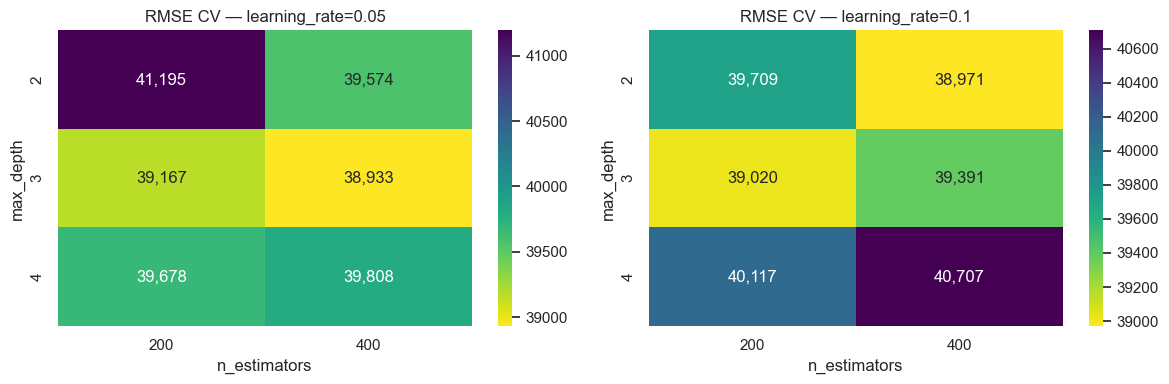

In [14]:
# Effet de max_depth x n_estimators, pour chaque learning_rate (imputer fixé au meilleur)
best_imputer = grid.best_params_["preprocess__num__imputer__strategy"]
subset = res[res["param_preprocess__num__imputer__strategy"] == best_imputer]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
for ax, lr in zip(axes, param_grid["model__learning_rate"]):
    pivot = (subset[subset["param_model__learning_rate"] == lr]
             .pivot_table(index="param_model__max_depth", columns="param_model__n_estimators", values="mean_test_RMSE")
             .mul(-1))
    sns.heatmap(data=pivot, annot=True, fmt=",.0f", cmap="viridis_r", ax=ax)
    ax.set_title(f"RMSE CV — learning_rate={lr}")
    ax.set_xlabel("n_estimators")
    ax.set_ylabel("max_depth")
plt.tight_layout()

**Lecture :** `learning_rate` et `n_estimators` se **compensent** (pas plus petit → il faut plus
d'arbres). Une profondeur trop grande finit par sur-apprendre. Le choix de l'imputation
change peu le résultat ici (8 % de valeurs manquantes, MCAR).

Le gain apporté par la recherche est **faible** par rapport aux paramètres par défaut : c'est
fréquent. Le choix du **type de modèle** et des **variables** pèse en général bien plus que le
réglage fin des hyperparamètres.

> Variante quand la grille devient trop grande : `RandomizedSearchCV` (tirage aléatoire d'un
> nombre fixe de combinaisons) ou des outils comme Optuna.

## 7. Évaluation finale sur le jeu de test

On compare sur le test (jamais vu) le modèle optimisé à quelques références entraînées sur tout le train.
Un score de test **proche** du score de validation croisée indique une estimation fiable.

In [15]:
def evaluate(model, name: str) -> dict:
    y_pred = model.predict(X_test)
    return {
        "modèle": name,
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100,
        "R2": r2_score(y_test, y_pred),
    }


references = ["Baseline (moyenne)", "Régression linéaire", "Linéaire sur log(prix)", "Random Forest", "Gradient Boosting"]
test_rows = [evaluate(make_pipeline(models[n]).fit(X_train, y_train), n) for n in references]
best_model = grid.best_estimator_
test_rows.append(evaluate(best_model, "Gradient Boosting optimisé"))

test_results = pd.DataFrame(data=test_rows).set_index("modèle")
test_results["RMSE CV"] = cv_results["RMSE"].reindex(test_results.index)
test_results.loc["Gradient Boosting optimisé", "RMSE CV"] = -grid.best_score_
test_results

,RMSE,MAE,MAPE (%),R2,RMSE CV
modèle,,,,,
Baseline (moyenne),"133,047.323","103,549.035",55.745,-0.001,"132,087.623"
Régression linéaire,"53,376.391","39,926.644",20.214,0.839,"54,317.903"
Linéaire sur log(prix),"58,242.622","37,643.491",15.739,0.808,"56,146.035"
Random Forest,"41,958.380","29,413.373",12.300,0.900,"41,737.322"
Gradient Boosting,"41,439.259","28,667.823",11.883,0.903,"39,148.449"
Gradient Boosting optimisé,"40,967.052","28,092.686",11.385,0.905,"38,932.522"


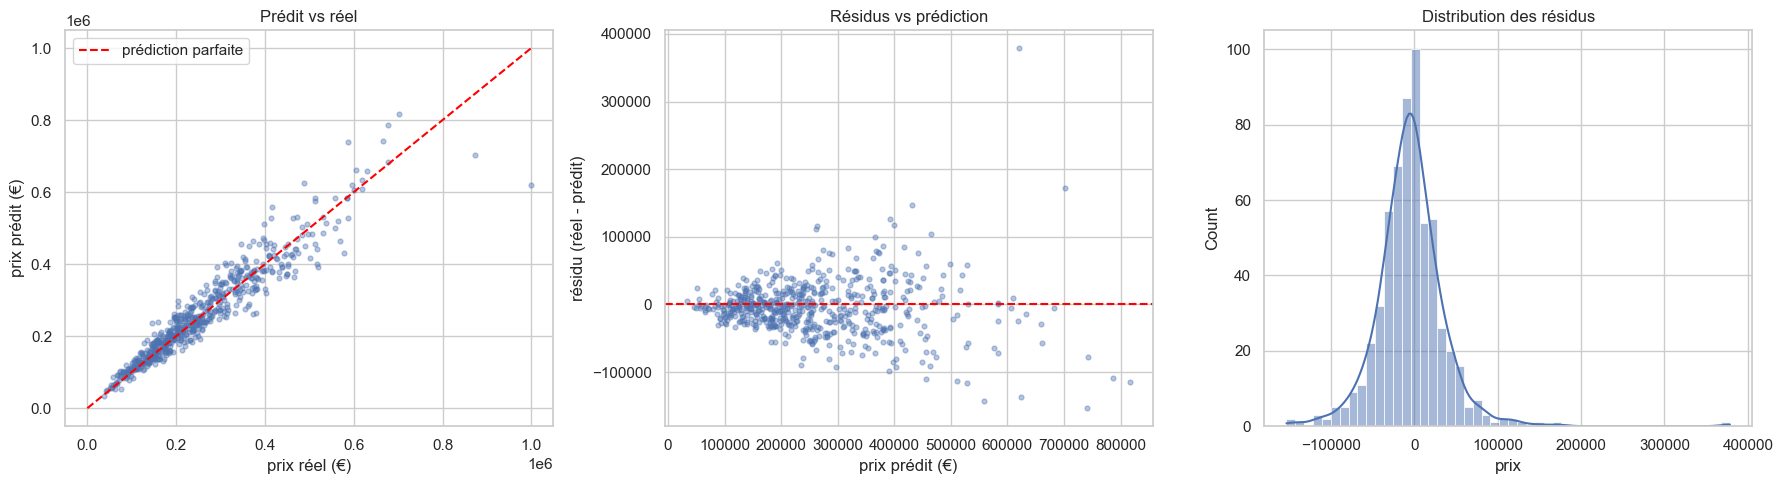

In [16]:
y_pred = best_model.predict(X_test)
residus = y_test - y_pred

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
axes[0].scatter(y_test, y_pred, alpha=0.4, s=12)
lim = [0, max(y_test.max(), y_pred.max())]
axes[0].plot(lim, lim, color="red", linestyle="--", label="prédiction parfaite")
axes[0].set(xlabel="prix réel (€)", ylabel="prix prédit (€)", title="Prédit vs réel")
axes[0].legend()

axes[1].scatter(y_pred, residus, alpha=0.4, s=12)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set(xlabel="prix prédit (€)", ylabel="résidu (réel - prédit)", title="Résidus vs prédiction")

sns.histplot(x=residus, bins=50, kde=True, ax=axes[2]).set_title("Distribution des résidus")
plt.tight_layout()

**Lecture du tableau :** le classement du test est le même qu'en validation croisée, et les
RMSE de test restent proches des RMSE de CV → l'estimation était fiable. Avec un bruit simulé
de ±12 %, l'erreur relative ne peut pas descendre sous ~10 % : le modèle optimisé (MAPE ≈ 11 %)
est proche de ce **plancher irréductible**.

**Lecture des graphiques de résidus :**
- *Prédit vs réel* : les points doivent suivre la diagonale ;
- *Résidus vs prédiction* : nuage centré sur 0 sans structure = le modèle a capté la tendance.
  Ici l'**entonnoir** (erreurs plus grandes pour les biens chers) est **attendu** : le bruit
  simulé est multiplicatif (±12 % du prix) → l'erreur en € grandit avec le prix (hétéroscédasticité) ;
- *Distribution* : centrée sur 0 (pas de biais systématique).

In [17]:
# Erreur par segment : le modèle est-il aussi bon partout ?
analyse = X_test.assign(prix=y_test, prediction=y_pred, erreur_abs=residus.abs(), erreur_pct=(residus.abs() / y_test * 100))
analyse.groupby(by="quartier")[["prix", "erreur_abs", "erreur_pct"]].mean().sort_values(by="prix", ascending=False)

,prix,erreur_abs,erreur_pct
quartier,,,
Centre,"314,193.600","36,049.298",12.107
Péricentre,"287,142.654","31,344.475",10.744
Banlieue,"223,261.413","23,042.589",10.753
Campagne,"156,206.250","18,699.111",13.399


## 8. Interprétation

### 8.1 Importance des variables par permutation

On mélange une colonne du test et on mesure la **dégradation** du score : plus elle est forte,
plus le modèle s'appuie sur cette variable. La méthode marche avec n'importe quel modèle et
travaille sur les **colonnes d'origine** (avant one-hot).

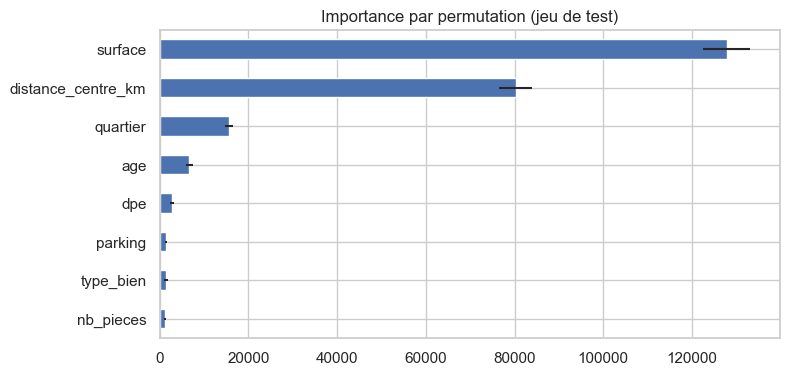

In [18]:
perm = permutation_importance(best_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
importances = pd.DataFrame(data={"hausse RMSE (€)": perm.importances_mean, "écart-type": perm.importances_std},
                           index=X_test.columns).sort_values(by="hausse RMSE (€)")
importances.plot.barh(y="hausse RMSE (€)", xerr="écart-type", legend=False, figsize=(8, 4),
                      title="Importance par permutation (jeu de test)");

**Lecture :** on retrouve les ingrédients de la formule simulée : la **surface** et le
**quartier** dominent, puis l'âge, le DPE, la distance et le parking. `nb_pieces` pèse peu :
l'information est déjà portée par la surface (colinéarité).

### 8.2 Courbe d'apprentissage

Plus de données amélioreraient-elles le modèle ?

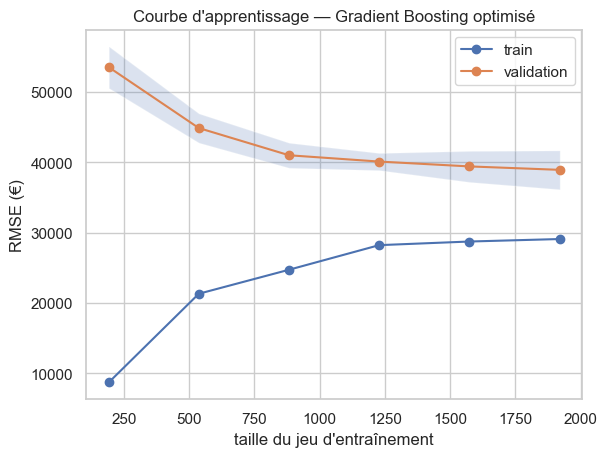

In [19]:
sizes, train_scores, val_scores = learning_curve(
    best_model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1,
)
plt.plot(sizes, -train_scores.mean(axis=1), marker="o", label="train")
plt.plot(sizes, -val_scores.mean(axis=1), marker="o", label="validation")
plt.fill_between(sizes, -val_scores.mean(axis=1) - val_scores.std(axis=1),
                 -val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel("taille du jeu d'entraînement")
plt.ylabel("RMSE (€)")
plt.title("Courbe d'apprentissage — Gradient Boosting optimisé")
plt.legend();

**Lecture :** si les deux courbes se rejoignent et se stabilisent, ajouter des données ne
servira plus beaucoup : on approche de l'erreur **irréductible** (le bruit de ±12 % simulé).
Un écart persistant train / validation signalerait du sur-apprentissage (→ plus de données
ou plus de régularisation).

## 9. Sauvegarde et prédiction sur de nouveaux biens

In [20]:
from pathlib import Path

MODEL_PATH = Path("models/regression_prix_logement.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(value=best_model, filename=MODEL_PATH)  # tout le pipeline : prétraitement + modèle

model = joblib.load(filename=MODEL_PATH)
nouveaux = pd.DataFrame(data=[
    {"surface": 45, "nb_pieces": 2, "age": 10, "distance_centre_km": 1.0, "quartier": "Centre",
     "type_bien": "Appartement", "dpe": "C", "parking": 0},
    {"surface": 120, "nb_pieces": 5, "age": 30, "distance_centre_km": 10.0, "quartier": "Banlieue",
     "type_bien": "Maison", "dpe": "D", "parking": 1},
    {"surface": 90, "nb_pieces": 4, "age": np.nan, "distance_centre_km": 25.0, "quartier": "Campagne",
     "type_bien": "Maison", "dpe": None, "parking": 1},  # valeurs manquantes gérées par le pipeline
])
nouveaux.assign(prix_estime=model.predict(nouveaux).round(-3))

,surface,nb_pieces,age,distance_centre_km,quartier,type_bien,dpe,parking,prix_estime
0,45,2,10.000,1.000,Centre,Appartement,C,0,"239,000.000"
1,120,5,30.000,10.000,Banlieue,Maison,D,1,"335,000.000"
2,90,4,NaN,25.000,Campagne,Maison,None,1,"136,000.000"


## 10. Synthèse

| Étape | À retenir |
|---|---|
| Découpage | test isolé **avant** toute préparation ; validation croisée sur le train |
| Préparation | `ColumnTransformer` + `Pipeline` → pas de fuite, un seul objet à déployer |
| Cible | transformation `log` utile si la cible est asymétrique / effets multiplicatifs (`TransformedTargetRegressor`) |
| Modèles | toujours une **baseline** ; linéaires = interprétables ; ensembles d'arbres = non-linéarités et interactions |
| Métriques | MAE (lisible), RMSE (pénalise les grosses erreurs), R² (part expliquée), MAPE (relatif) |
| Hyperparamètres | `GridSearchCV` sur le pipeline entier (`etape__parametre`), `refit` sur la métrique choisie |
| Évaluation | test utilisé **une seule fois** ; comparer à la CV ; analyser les résidus et les segments |
| Interprétation | importance par permutation, courbe d'apprentissage |

**Pistes d'amélioration :** encodage **ordinal** du DPE (A < B < ... < G), variables construites
(prix au m² du quartier, surface par pièce), `HistGradientBoostingRegressor` (plus rapide, gère
les NaN nativement), `RandomizedSearchCV` / Optuna pour des grilles plus larges, intervalles de
prédiction (régression quantile).